Original Dataset:
   Car_ID  Engine_CC  Horsepower  Mileage  Weight_kg  Top_Speed  Acceleration  \
0       1        800          45       22        850        140            15   
1       2       1000          65       20        950        155            13   
2       3       1200          85       18       1100        170            11   
3       4       1500         110       16       1250        185             9   
4       5       2000         150       14       1400        210             8   

   Seating_Capacity  Price_Lakhs  
0                 5          4.5  
1                 5          5.5  
2                 5          7.0  
3                 5         10.0  
4                 5         15.0  

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Car_ID            20 non-null     int64  
 1   Engine_CC         20 non-n

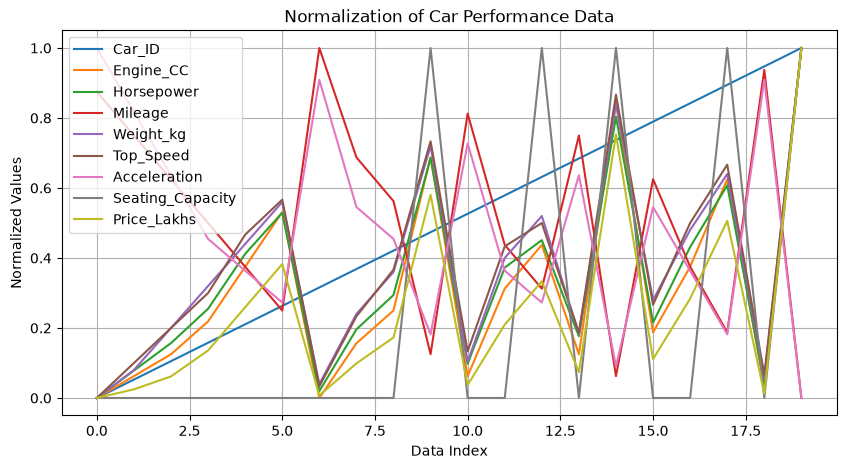


Standardized Data:
     Car_ID  Engine_CC  Horsepower   Mileage  Weight_kg  Top_Speed  \
0 -1.647509  -1.137573   -1.268553  1.249118  -1.371983  -1.384330   
1 -1.474087  -0.915608   -0.976932  0.818388  -1.077882  -1.020989   
2 -1.300665  -0.693642   -0.685310  0.387657  -0.636730  -0.657648   
3 -1.127243  -0.360694   -0.320784 -0.043073  -0.195577  -0.294306   
4 -0.953821   0.194220    0.262459 -0.473804   0.245575   0.311262   

   Acceleration  Seating_Capacity  Price_Lakhs  
0      1.840137          -0.57735    -0.946876  
1      1.188761          -0.57735    -0.854181  
2      0.537385          -0.57735    -0.715139  
3     -0.113991          -0.57735    -0.437055  
4     -0.439679          -0.57735     0.026418  


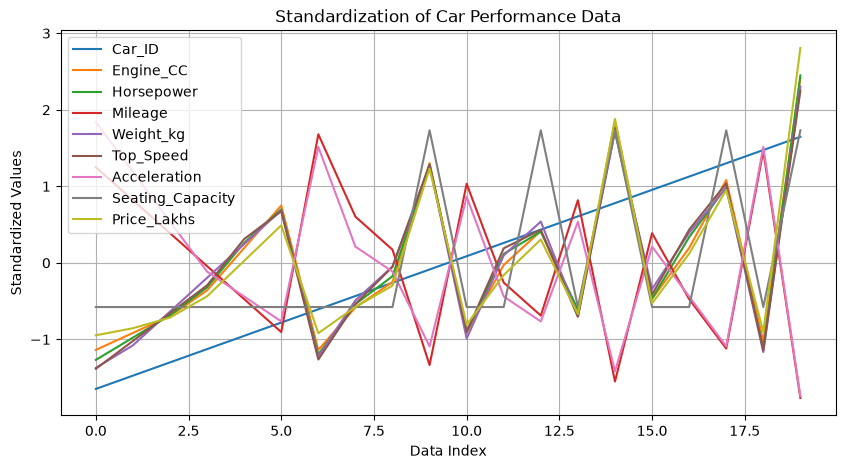


PCA Reduced Data:
        PC1       PC2
0 -3.730427 -0.774964
1 -2.872897 -0.867524
2 -1.946420 -0.971080
3 -0.905303 -1.087697
4  0.333512 -1.210199


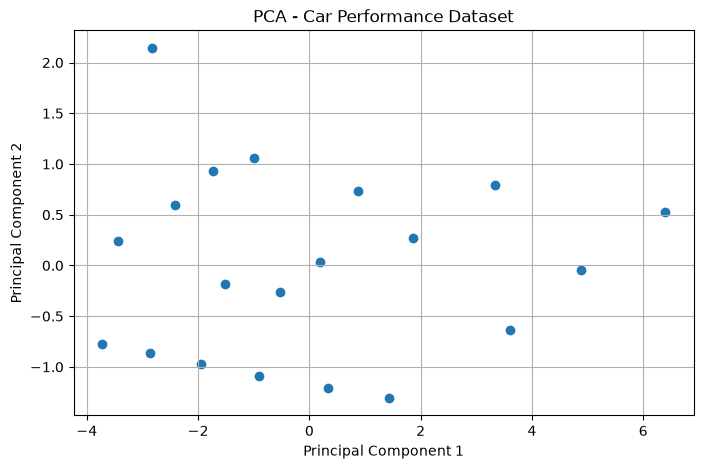

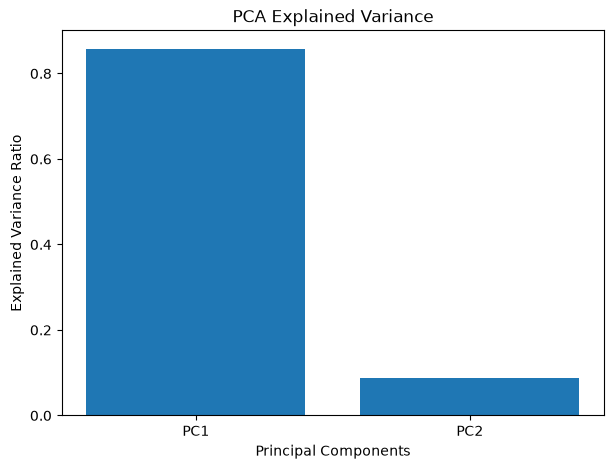


Explained Variance Ratio:
[0.85770401 0.0872339 ]

Total Explained Variance:
0.9449379116197827

Feature Engineering Completed Successfully!


In [4]:

# Feature Engineering: Normalization, Standardization and PCA
# Dataset: car_performance.csv

# Step 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

# Step 2: Load dataset
df = pd.read_csv("car_performance.csv")

print("Original Dataset:")
print(df.head())

print("\nDataset Information:")
print(df.info())

# Step 3: Select numerical columns
numeric_data = df.select_dtypes(include=np.number)

# Remove columns containing only missing values
numeric_data = numeric_data.dropna(axis=1, how='all')

print("\nNumerical Data:")
print(numeric_data.head())

# Step 4: Handle missing values
imputer = SimpleImputer(strategy='median')
clean_data = imputer.fit_transform(numeric_data)

clean_df = pd.DataFrame(
    clean_data, columns=numeric_data.columns
)

# Step 5: Normalization
normalizer = MinMaxScaler()
normalized_data = normalizer.fit_transform(clean_df)

normalized_df = pd.DataFrame(
    normalized_data, columns=clean_df.columns
)

print("\nNormalized Data:")
print(normalized_df.head())

# Plot Normalization
plt.figure(figsize=(10, 5))

for column in normalized_df.columns:
    plt.plot(normalized_df.index[:50],
             normalized_df[column][:50],
             label=column)

plt.title("Normalization of Car Performance Data")
plt.xlabel("Data Index")
plt.ylabel("Normalized Values")
plt.legend()
plt.grid()
plt.show()

# Step 6: Standardization
scaler = StandardScaler()
standardized_data = scaler.fit_transform(clean_df)

standardized_df = pd.DataFrame(
    standardized_data, columns=clean_df.columns
)

print("\nStandardized Data:")
print(standardized_df.head())

# Plot Standardization
plt.figure(figsize=(10, 5))

for column in standardized_df.columns:
    plt.plot(standardized_df.index[:50],
             standardized_df[column][:50],
             label=column)

plt.title("Standardization of Car Performance Data")
plt.xlabel("Data Index")
plt.ylabel("Standardized Values")
plt.legend()
plt.grid()
plt.show()

# Step 7: Principal Component Analysis (PCA)
if standardized_data.shape[1] < 2:
    raise ValueError("PCA requires at least two numerical features.")

pca = PCA(n_components=2)
pca_data = pca.fit_transform(standardized_data)

pca_df = pd.DataFrame(
    pca_data, columns=['PC1', 'PC2']
)

print("\nPCA Reduced Data:")
print(pca_df.head())

# Plot PCA
plt.figure(figsize=(8, 5))

plt.scatter(pca_df['PC1'], pca_df['PC2'])

plt.title("PCA - Car Performance Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid()
plt.show()

# Step 8: Explained Variance
plt.figure(figsize=(7, 5))

plt.bar(['PC1', 'PC2'], pca.explained_variance_ratio_)

plt.title("PCA Explained Variance")
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.show()

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(sum(pca.explained_variance_ratio_))

print("\nFeature Engineering Completed Successfully!")
